In [2]:
import re
import os
import fitz
import warnings
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.sequence import pad_sequences

c:\Users\namya\AppData\Local\Programs\Python\Python312\Lib\site-packages\fitz\__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


In [3]:
# To Hide All The Irrelevant Logs And Warrings Which Are Showed When Using The GPU
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

In [4]:
# To Check If The Tensorflow Is fetching The GPU Or Not
print("TensorFlow version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPUs: []


## **Next Word Prediction Using Recurrent Neural Network (RNN)**

### Q1 Load And Explore and Clean The Dataset.

In [7]:
# Check files in the current working directory
pdf_path = Path(r"C:\Users\namya\Documents\Red and White\Deep Learning\PR - 5\85jkr_harrypotter_1.pdf")

text = ""

with fitz.open(pdf_path) as pdf:
    # Range Upto 10 Means We Have Used Only 10 Pages Of The PDF Because It is An RNN Model And It can Only Remenber A Limited Number Of Words(30)
    for page in pdf[:10]:          
        text += page.get_text() + "\n"

print(text[:1000])


1
Harry Potter and the Sorcerer's Stone
CHAPTER ONE
THE BOY WHO LIVED
Mr. and Mrs. Dursley, of number four, Privet Drive, were proud to say
that they were perfectly normal, thank you very much. They were the last
people you'd expect to be involved in anything strange or mysterious,
because they just didn't hold with such nonsense.
Mr. Dursley was the director of a firm called Grunnings, which made
drills. He was a big, beefy man with hardly any neck, although he did
have a very large mustache. Mrs. Dursley was thin and blonde and had
nearly twice the usual amount of neck, which came in very useful as she
spent so much of her time craning over garden fences, spying on the
neighbors. The Dursleys had a small son called Dudley and in their
opinion there was no finer boy anywhere.
The Dursleys had everything they wanted, but they also had a secret, and
their greatest fear was that somebody would discover it. They didn't
think they could bear it if anyone found out about the Potters. Mrs.


- We Have Loaded The Corpus with the help of pathlib and encoding with the utf-8.

In [8]:
# Exploring The Dataset
print("Total Characters:", len(text))
print("Total Words:", len(text.split()))
print("Total Lines:", len(text.splitlines()))

Total Characters: 19274
Total Words: 3475
Total Lines: 327


In [9]:
# Check unique words before preprocessing
print("Unique Words:", len(set(text.split())))

Unique Words: 1304


- This helps us identify capitalization, punctuation, line breaks, and other text patterns that may need cleaning.

In [10]:
# Convert text to lowercase
cleaned_text = text.lower()

# Remove unwanted characters while keeping basic punctuation
cleaned_text = re.sub(r"[^a-z0-9\s.,!?;:'\"-]", "", cleaned_text)

# Normalize extra whitespace
cleaned_text = re.sub(r"\s+", " ", cleaned_text).strip()

# Remove spaces from the beginning and end
text = text.strip()
print(cleaned_text)

1 harry potter and the sorcerer's stone chapter one the boy who lived mr. and mrs. dursley, of number four, privet drive, were proud to say that they were perfectly normal, thank you very much. they were the last people you'd expect to be involved in anything strange or mysterious, because they just didn't hold with such nonsense. mr. dursley was the director of a firm called grunnings, which made drills. he was a big, beefy man with hardly any neck, although he did have a very large mustache. mrs. dursley was thin and blonde and had nearly twice the usual amount of neck, which came in very useful as she spent so much of her time craning over garden fences, spying on the neighbors. the dursleys had a small son called dudley and in their opinion there was no finer boy anywhere. the dursleys had everything they wanted, but they also had a secret, and their greatest fear was that somebody would discover it. they didn't think they could bear it if anyone found out about the potters. mrs. p

- lower() makes words consistent, so Alice and alice become the same token.
- re.sub() removes unwanted characters while retaining common punctuation.
- Extra spaces and line breaks are normalized.

In [11]:
print("Total Characters:", len(cleaned_text))
print("Total Words:", len(cleaned_text.split()))
print("Total Lines:", len(cleaned_text.splitlines()))

Total Characters: 19261
Total Words: 3475
Total Lines: 1


### Q2 How do we tokenize the text and How do we create input sequences and target words?

In [12]:
# Split the cleaned corpus at a word boundary
train_end = int(len(cleaned_text) * 0.80)
train_end = cleaned_text.rfind(" ", 0, train_end)

val_end = int(len(cleaned_text) * 0.90)
val_end = cleaned_text.rfind(" ", train_end + 1, val_end)

train_text = cleaned_text[:train_end].strip()
val_text = cleaned_text[train_end:val_end].strip()
test_text = cleaned_text[val_end:].strip()

# Initialize the tokenizer
tokenizer = tf.keras.preprocessing.text.Tokenizer(oov_token="<OOV>")

# Learn vocabulary from training text only
tokenizer.fit_on_texts([train_text])

# Convert both text splits into numerical word IDs
train_sequences = tokenizer.texts_to_sequences([train_text])[0]
test_sequences = tokenizer.texts_to_sequences([test_text])[0]
val_sequences = tokenizer.texts_to_sequences([val_text])[0]

print("Vocabulary Size:", len(tokenizer.word_index))
print("Training Tokens:", len(train_sequences))
print("Validation Tokens:", len(val_sequences))
print("Testing Tokens:", len(test_sequences))

print("\nFirst 10 training token IDs:", train_sequences[:10])

Vocabulary Size: 838
Training Tokens: 2799
Validation Tokens: 338
Testing Tokens: 333

First 10 training token IDs: [350, 82, 83, 6, 2, 351, 352, 353, 155, 2]


In [13]:
# Display the first 10 words with their IDs
print("First 10 word mappings:")

for word, index in list(tokenizer.word_index.items())[:10]:
    print(word, "->", index)

First 10 word mappings:
<OOV> -> 1
the -> 2
he -> 3
a -> 4
was -> 5
and -> 6
to -> 7
of -> 8
it -> 9
dursley -> 10


- Tokenizer() creates a tokenizer object.
- fit_on_texts() identifies unique words and assigns each a numerical ID.
- word_index stores the mapping between words and their IDs.
- The most frequent words generally receive lower IDs.
- The text is now represented as a sequence of integers. Each integer corresponds to a word in the vocabulary.

In [14]:
# Creating Sequences To Create Examples For RNN Model
def create_sequences(token_sequence, sequence_length=5):
    input_sequences = []

    for i in range(sequence_length, len(token_sequence)):
        sequence = token_sequence[i - sequence_length:i + 1]
        input_sequences.append(sequence)

    return input_sequences

train_input_sequences = create_sequences(train_sequences,sequence_length=5)
test_input_sequences = create_sequences(test_sequences,sequence_length=5)
val_input_sequences = create_sequences(test_sequences, 5)

print("Training sequences:", len(train_input_sequences))
print("Testing sequences:", len(test_input_sequences))
print("Validation sequences:", len(val_sequences))
print("Sample training sequences:", train_input_sequences[:5])

Training sequences: 2794
Testing sequences: 328
Validation sequences: 338
Sample training sequences: [[350, 82, 83, 6, 2, 351], [82, 83, 6, 2, 351, 352], [83, 6, 2, 351, 352, 353], [6, 2, 351, 352, 353, 155], [2, 351, 352, 353, 155, 2]]


- We are creating sequences because an RNN needs examples of previous words and the next word it should predict.
- The function Is Selecting 5 previous words plus one target word to tell the RNN what sequences the corpus is holding.

### Q3 How do we separate the input words (X) and target words (y)?

In [15]:
# Convert sequences into NumPy arrays
train_array = np.array(train_input_sequences)
val_array = np.array(val_input_sequences)
test_array = np.array(test_input_sequences)

# Separate input words and target words
X_train = train_array[:, :-1]
y_train = train_array[:, -1]

X_val = val_array[:, :-1]
y_val = val_array[:, -1]

X_test = test_array[:, :-1]
y_test = test_array[:, -1]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (2794, 5)
y_train shape: (2794,)
X_val shape: (328, 5)
y_val shape: (328,)
X_test shape: (328, 5)
y_test shape: (328,)


- X_train contains the five preceding word IDs.
- y_train contains the next word ID the model must predict.
- X_test and y_test are used to evaluate the model on held-out text.
- [:, :-1] selects all columns except the last.
- [:, -1] selects only the last column.

In [16]:
# Verifying The Data
print("Sample input IDs:", X_train[0])
print("Target ID:", y_train[0])

print("Input words:",tokenizer.sequences_to_texts([X_train[0]])[0])
print("Target word:",tokenizer.index_word.get(y_train[0], "<UNKNOWN>"))

Sample input IDs: [350  82  83   6   2]
Target ID: 351
Input words: 1 harry potter and the
Target word: sorcerer's


- We Checked That your input consists of words and the target is the next word.

### Q4 How To Create An RNN Model And What Shape We Should Choose.

In [ ]:
# Define vocabulary size
vocab_size = len(tokenizer.word_index) + 1

# Build the RNN model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(5,)),   # Accepts 5 token IDs as input because the model was designed to use the previous five words to predict the next word. 

    tf.keras.layers.Embedding(input_dim=vocab_size,output_dim=64,mask_zero=True),  # Converts each token ID into a dense vector of 64 numbers.

    tf.keras.layers.SimpleRNN(128),   # Learns sequential patterns from the five word embeddings using 128 recurrent units.
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(vocab_size,activation="softmax")
])
# Display model architecture
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 5, 64)          │        53,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 128)            │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 839)            │       108,231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 186,631 (729.03 KB)

 Trainable params: 186,631 (729.03 KB)

 Non-trainable params: 0 (0.00 B)

- This code builds an RNN model for next-word prediction. It takes five words as input, learns patterns in their sequence, and predicts the next word from the vocabulary.

In [41]:
# Compiling And Fitting The Model
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

# Early stopping and learning rate reduction callbacks
early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True,verbose=1)

# ReduceLROnPlateau reduces the learning rate when validation loss stops improving. This can help the model converge more carefully.
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=1,min_lr=1e-6,verbose=1)

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_val,y_val),
    # callbacks=[reduce_lr,early_stopping],
    verbose=1)

Epoch 1/30


I0000 00:00:1792672520.051976    1415 dot_merger.cc:481] Merging Dots in computation: sequential_2_1_simple_rnn_2_1_while_body_55807_grad_56020_const_0__.22.clone.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1792672520.052290    1415 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_56607__.25


87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0316 - loss: 6.3109

I0000 00:00:1792672526.063056    1415 dot_merger.cc:481] Merging Dots in computation: sequential_2_1_simple_rnn_2_1_while_body_55807_grad_56020_const_0__.22.clone.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:1792672526.063301    1415 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_56607__.25


88/88 ━━━━━━━━━━━━━━━━━━━━ 19s 132ms/step - accuracy: 0.0319 - loss: 6.3105 - val_accuracy: 0.0305 - val_loss: 6.3488
Epoch 2/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.0483 - loss: 5.8431 - val_accuracy: 0.0305 - val_loss: 6.5669
Epoch 3/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.0569 - loss: 5.6898 - val_accuracy: 0.0305 - val_loss: 6.6355
Epoch 4/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.0694 - loss: 5.4405 - val_accuracy: 0.0274 - val_loss: 6.9671
Epoch 5/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.1056 - loss: 5.0545 - val_accuracy: 0.0305 - val_loss: 6.7968
Epoch 6/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.1500 - loss: 4.6229 - val_accuracy: 0.0274 - val_loss: 6.8661
Epoch 7/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.2133 - loss: 4.1995 - val_accuracy: 0.0213 - val_loss: 7.0965
Epoch 8/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.2831 - loss: 3.7993 - val_accuracy: 0.0244 - val_loss: 

- This code compiles and trains your RNN model for next-word prediction. It configures how the model learns, how errors are measured, and how training data is processed over multiple epochs.
- We Have Commented Callbacks because Right Now The Model Training Doesn't need If In Future The Dataset Size Increases We Will Use it.

In [53]:
# Model Evaluation
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print("Test accuracy:", round(test_accuracy * 100, 2), "%")
print("Test accuracy:", test_loss)

Test accuracy: 2.74 %
Test accuracy: 9.84469223022461


- We Can Say That Validation Accuracy Is Not Good Enough For The Model But The Model Actually Performs Good When It Is Predicting Below So a Low Validation Accuracy Is Not A Threat Because The Model Is Performing Good. 

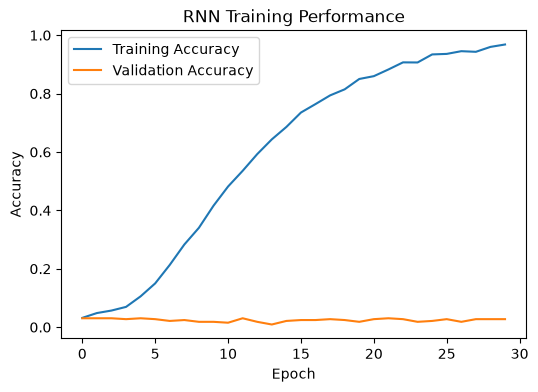

In [43]:
# Plotting The Validation And Training Accuracy Curve
plt.figure(figsize=(6,4))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("RNN Training Performance")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [45]:
print("Training accuracy:", history.history["accuracy"][-1])
print("Validation accuracy:", history.history["val_accuracy"][-1])
print("Training loss:", history.history["loss"][-1])
print("Validation loss:", history.history["val_loss"][-1])

Training accuracy: 0.968146026134491
Validation accuracy: 0.027439024299383163
Training loss: 0.3326667845249176
Validation loss: 9.84469223022461


### Q5 Predicting The Next Words From Random Input.

In [ ]:
# Predicting The Next Words Using An Random Input From The Data Like Picking Up An Sentence of 5 To 6 And RNN Model Will Generate The Next 5 Words
def predict_next_words(seed_text, num_words=10):
    generated_text = seed_text

    for _ in range(num_words):
        # Convert text into token IDs
        token_list = tokenizer.texts_to_sequences([generated_text])[0]

        # Keep the last 5 tokens
        token_list = token_list[-5:]

        # Ensure input has exactly 5 tokens
        token_list = pad_sequences(
            [token_list],
            maxlen=5,  # Your model expects 5 input words
            padding="pre",
            truncating="pre")

        # Predict the next word
        predictions = model.predict(token_list, verbose=0)
        predicted_id = np.argmax(predictions[0])

        # Convert predicted ID into a word
        predicted_word = tokenizer.index_word.get(predicted_id, "<UNKNOWN>")

        # Stop if no valid word is predicted
        if predicted_word == "<UNKNOWN>" or predicted_word == "<OOV>":
            break

        # Append predicted word to generated text
        generated_text += " " + predicted_word
    return generated_text

seed_text = "He was a big, beefy man with"
next_text = predict_next_words(seed_text, num_words=10)

print("Input text:", seed_text)
print("Generated text:", next_text)

Input text: He was a big, beefy man with
Generated text: He was a big, beefy man with hardly any neck although he did have a very large


- pad_sequences():Ensures the input has exactly five tokens.
- tokenizer.index_word.get():Converts the predicted token ID back into a word.
- np.argmax():Selects the word with the highest predicted probability.

- This code implements text generation using a trained RNN. It converts the starting text into tokens, predicts the most likely next word, appends that word to the text, and repeats the process to generate a longer sequence.

In [55]:
# Saving The Model Prevent The Problem Of Running And Preprocessing Everytime
model.save("next_word_rnn.keras")
print("Model saved successfully!")

Model saved successfully!


In [17]:
# Saving The Tokenizer Because my Prediction function needs the same word to token mapping used during training
import pickle
with open("tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file) 